<a href="https://colab.research.google.com/github/ZainabIftikhar1204/DL-for-Space-Time-and-Graphs---Assignment-2/blob/main/DL_STG_Assg_2_Q2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Question 2 AHHH

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F

In [14]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [10]:
# some defaults for models
LEARNING_RATE = 0.001
BATCH_SIZE = 32
EPOCHS = 30

In [11]:
def optimizer(params):
  return torch.optim.Adam(params, lr=LEARNING_RATE)

In [13]:
def mse_loss(y_hat, y, mask):
    # squared error averaged over pixels -> one number per (video, frame)
    se = ((y_hat - y) ** 2).mean(dim=(2, 3, 4))          # (B,5)

    #average over each video's available frames only
    #mask -> zeros out padded frames
    per_video = (se * mask).sum(dim=1) / mask.sum(dim=1)  # (B,)

    # average over videos: every video counts equally
    return per_video.mean()

### Setup

In [ ]:
def rotate(data, rotations=1):
  # Apply requested number of 90-degree rotations (k = 0, 1, 2, 3, 4)
  if rotations % 4 != 0:
    data = torch.rot90(data, k=rotations % 4, dims=[-2, -1])
  return data

In [ ]:
def mirror(data, mirror=1):
  # Apply horizontal mirroring efficiently:
  # Flipping an even number of times does nothing. An odd number of times is equal to a single flip.
  if mirror % 2 != 0:
    data = torch.flip(data, dims=[-1])
  return data

In [ ]:
def speed_up(data, stride = 1):
  data = data[::stride]
  return data

In [ ]:
def transform_data(data, stride=1, rotations=0, mirror_num=0):
  # Convert the video sequence to float32 and normalize
  data = data.float() / 255.0
  # Speed up / stride
  data = speed_up(data, stride)
  #mirror
  data = mirror(data, mirror_num)
  #rotate
  data = rotate(data, rotations)

  return data

In [ ]:
# lets load the data shall we?
data = torchvision.datasets.MovingMNIST(root='./data',
                                        download=True,
                                        split=None,
                                        transform=lambda x: transform_data(x, stride=1)
                                        )
data

Dataset MovingMNIST
    Number of datapoints: 10000
    Root location: ./data
    StandardTransform
Transform: <function <lambda> at 0x7d4083466160>

In [ ]:
import torch
from torch.utils.data import Subset

# Define your split sizes or specific indices
total_size = len(data)
train_size = 8000
val_size = 1000

# Generate indices
indices = torch.randperm(total_size).tolist()

train_indices = indices[:train_size]
val_indices = indices[train_size:train_size + val_size]
test_indices = indices[train_size + val_size:]

# Create Subsets
train_dataset = Subset(data, train_indices)
val_dataset = Subset(data, val_indices)
test_dataset = Subset(data, test_indices)

print(f"Train size: {len(train_dataset)}")
print(f"Validation size: {len(val_dataset)}")
print(f"Test size: {len(test_dataset)}")

Train size: 8000
Validation size: 1000
Test size: 1000


In [ ]:
train_dataset.dataset.data[0][0]

tensor([[[0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         ...,
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0]]], dtype=torch.uint8)

In [ ]:
# Let's check the shape of the underlying data
print("Underlying raw data shape:", data.data.shape)

# Let's inspect a single sequence from the dataset
first_sequence = data[0]
print("Single dataset item shape/length:", first_sequence.shape if torch.is_tensor(first_sequence) else len(first_sequence))

Underlying raw data shape: torch.Size([10000, 20, 1, 64, 64])
Single dataset item shape/length: torch.Size([20, 1, 64, 64])


In [ ]:
# Extract the 1st sequence: shape is (20, 1, 64, 64)
video_sequence = data[0]

# Extract the 1st frame: shape is (1, 64, 64)
first_frame = video_sequence[0]

# Plot the frame using Matplotlib
plt.figure(figsize=(4, 4))
plt.imshow(first_frame.squeeze(), cmap='gray')
plt.title("First Frame of Sequence 0")
plt.axis('off')
plt.show()

## Checks for transformations

In [ ]:
## Checking if transformations are right or if i messed up
torch.manual_seed(0)
x = torch.rand(20, 1, 64, 64)
p = torch.zeros(20, 1, 64, 64)
p[7,0,10,20] = 1

In [ ]:
# check (a): max|M (M (x)) − x|
x_mm = mirror(x, 2)
torch.abs(x_mm - x).max()

tensor(0.)

In [ ]:
# check (b):max|R4 (x) − x|
x_r4 = rotate(x, 4)
torch.abs(x_r4 - x).max()

tensor(0.)

In [ ]:
#check (c): max|M RM (x) − R−1 (x)|
x_mrm = mirror(rotate(mirror(x), 1))
x_r_inv = rotate(x, -1)
torch.abs(x_mrm - x_r_inv).max()

tensor(0.)

In [ ]:
#check(d):bright pixel of M (p) (frame, row, column)
m_p = mirror(p)

# Find the value and the flat index of the maximum element
max_val = torch.max(m_p)
max_idx = torch.argmax(m_p)

# Unravel the flat index into multi-dimensional coordinates (frame, channel, row, col)
# m_p shape is [20, 1, 64, 64]
shape = m_p.shape
coords = np.unravel_index(max_idx.item(), shape)

frame, channel, row, col = coords
print(f"Maximum pixel value: {max_val.item()}")
print(f"Coordinates - ({frame}, {row}, {col})")


Maximum pixel value: 1.0
Coordinates - (7, 10, 43)


In [ ]:
#check (e): bright pixel of R(p) (frame, row, column)
r_p = rotate(p, 1)

# Find the value and the flat index of the maximum element
max_val = torch.max(r_p)
max_idx = torch.argmax(r_p)

# Unravel the flat index into multi-dimensional coordinates (frame, channel, row, col)
# r_p shape is [20, 1, 64, 64]
shape = r_p.shape
coords = np.unravel_index(max_idx.item(), shape)

frame, channel, row, col = coords
print(f"Maximum pixel value: {max_val.item()}")
print(f"Coordinates - ({frame}, {row}, {col})")

Maximum pixel value: 1.0
Coordinates - (7, 43, 10)


In [ ]:
LOOKBACK = 5
HORIZON = 5

In [ ]:
# 1. Grab a raw 20-frame sequence (bypassing dataset transform for demonstration)
raw_sequence = data.data[0] # shape: [20, 1, 64, 64]
print(f"Raw sequence shape: {raw_sequence.shape} (20 frames)")

# 2. Apply a speedup (e.g. stride = 2) to get 10 frames
stride_vals = [1, 2, 3]

for stride_val in stride_vals:
  print(f"\n----------STRIDE: {stride_val}------------")
  transformed_seq = raw_sequence[::stride_val]

  lookback_frames = transformed_seq[:LOOKBACK]
  target_frames = transformed_seq[LOOKBACK:LOOKBACK + HORIZON]

  print(f"Lookback Frames: {len(lookback_frames)}")
  print(f"Iindices from original raw 20 frames: {[(i * stride_val + 1) for i in range(LOOKBACK)]}")

  print(f"\nTarget / Horizon Frames: {len(target_frames)}")
  print(f"Iindices from original raw 20 frames: {[(i * stride_val + 1) for i in range(LOOKBACK, LOOKBACK + HORIZON)]}")

Raw sequence shape: torch.Size([20, 1, 64, 64]) (20 frames)

----------STRIDE: 1------------
Lookback Frames: 5
Iindices from original raw 20 frames: [1, 2, 3, 4, 5]

Target / Horizon Frames: 5
Iindices from original raw 20 frames: [6, 7, 8, 9, 10]

----------STRIDE: 2------------
Lookback Frames: 5
Iindices from original raw 20 frames: [1, 3, 5, 7, 9]

Target / Horizon Frames: 5
Iindices from original raw 20 frames: [11, 13, 15, 17, 19]

----------STRIDE: 3------------
Lookback Frames: 5
Iindices from original raw 20 frames: [1, 4, 7, 10, 13]

Target / Horizon Frames: 2
Iindices from original raw 20 frames: [16, 19, 22, 25, 28]


## Is training data symmetric? no clue

In [ ]:
dof_vids = train_dataset[:50]
dof_vids.data.shape

torch.Size([50, 20, 1, 64, 64])

In [ ]:
dof_vids_scaled = [sample * 255.0 for sample in dof_vids] #unit8 scale

In [ ]:
import cv2
import numpy as np

# List to store the calculated optical flows
# Each flow element will have a shape of (H, W, 2) representing (u, v) flow fields
all_flows = []

for video_idx, video_tensor in enumerate(dof_vids_scaled):
    # video_tensor has shape [20, 1, 64, 64] or [20, 64, 64]
    # Ensure we convert it to a numpy array of uint8
    video_np = video_tensor.squeeze().cpu().numpy().astype(np.uint8)

    video_flows = []
    for s in range(19):
        prev_frame = video_np[s]
        next_frame = video_np[s + 1]

        # Compute dense optical flow using Farneback's method with the specified parameters
        flow = cv2.calcOpticalFlowFarneback(
            prev=prev_frame,
            next=next_frame,
            flow=None,
            pyr_scale=0.5,
            levels=3,
            winsize=15,
            iterations=3,
            poly_n=5,
            poly_sigma=1.2,
            flags=0
        )
        video_flows.append(flow)
    all_flows.append(video_flows)

# Convert to numpy array for easier downstream analysis
# Shape should be (50, 19, 64, 64, 2)
all_flows_np = np.array(all_flows)
print("Computed flow array shape:", all_flows_np.shape)
print("Total frame pairs analyzed:", all_flows_np.shape[0] * all_flows_np.shape[1])

Computed flow array shape: (50, 19, 64, 64, 2)
Total frame pairs analyzed: 950


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Accumulate valid flows
filtered_dx_list = []
filtered_dy_list = []

# Iterate through each of the 50 videos
for video_idx in range(len(dof_vids_scaled)):
    video_np = dof_vids_scaled[video_idx].squeeze().cpu().numpy().astype(np.uint8)

    for s in range(19):
        prev_frame = video_np[s]
        next_frame = video_np[s + 1]
        flow_frame = all_flows_np[video_idx, s]  # shape (64, 64, 2)

        dx_frame = flow_frame[..., 0]
        dy_frame = flow_frame[..., 1]
        magnitude = np.sqrt(dx_frame**2 + dy_frame**2)

        # Create joint mask: intensity > 51 in both frames AND flow magnitude > 0.5
        cond = (prev_frame > 51) & (next_frame > 51) & (magnitude > 0.5)

        filtered_dx_list.extend(dx_frame[cond])
        filtered_dy_list.extend(dy_frame[cond])



### (a)histogram of flow direction

In [ ]:
num_pixels_kept = len(filtered_dx_list)
print(f"Number of raw pixels: {50*20*64*64}")
print(f"Number of pixels kept: {num_pixels_kept}")

Number of raw pixels: 4096000
Number of pixels kept: 103374


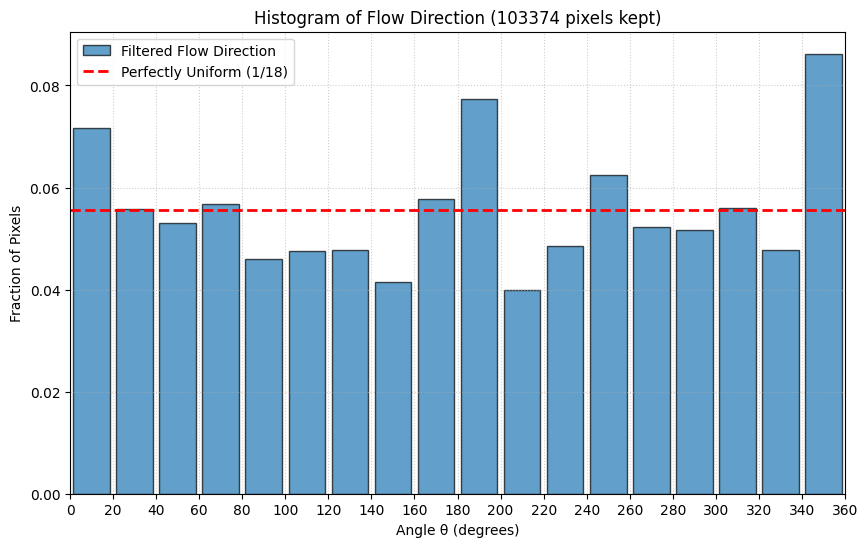

In [ ]:
# Convert to numpy arrays
filtered_dx = np.array(filtered_dx_list)
filtered_dy = np.array(filtered_dy_list)

# Calculate theta = atan2(-dy, dx)
theta_rad = np.arctan2(-filtered_dy, filtered_dx)
theta_deg = np.degrees(theta_rad) % 360.0

# Plot histogram
plt.figure(figsize=(10, 6))
bins = np.linspace(0, 360, 19)
weights = np.ones_like(theta_deg) / len(theta_deg)

plt.hist(theta_deg, bins=bins, weights=weights, edgecolor='black', alpha=0.7, rwidth=0.85, label='Filtered Flow Direction')
plt.axhline(y=1/18, color='r', linestyle='--', linewidth=2, label='Perfectly Uniform (1/18)')

plt.title(f'Histogram of Flow Direction ({num_pixels_kept} pixels kept)')
plt.xlabel('Angle θ (degrees)')
plt.ylabel('Fraction of Pixels')
plt.xticks(np.arange(0, 361, 20))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.xlim(0, 360)
plt.show()

### (b)histogram of flow speed

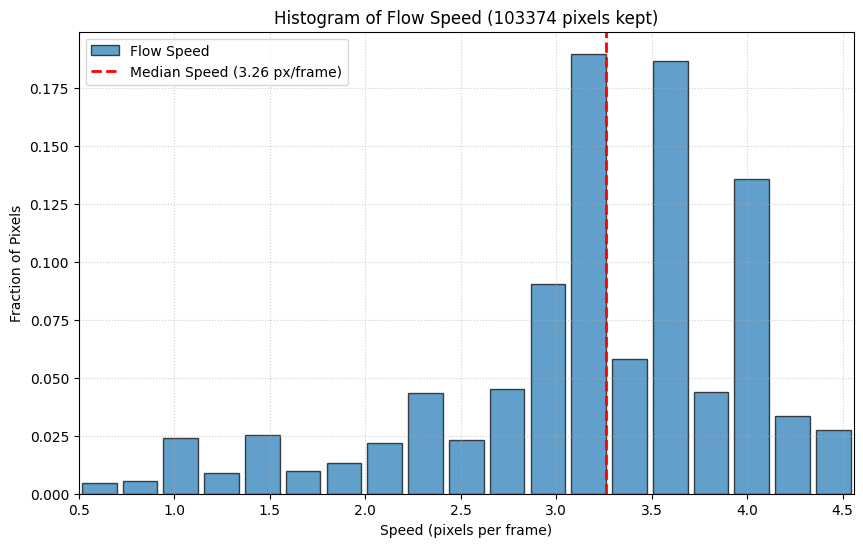

In [ ]:
# Calculate speed = sqrt(dx**2 + dy**2)
speed = np.sqrt(filtered_dx**2 + filtered_dy**2)

# Plot histogram
plt.figure(figsize=(10, 6))

# Dynamically set bins based on the maximum speed observed
max_speed = np.percentile(speed, 99)  # focus on 99% of data for a cleaner plot
bins = np.linspace(0.5, max_speed, 20)
weights = np.ones_like(speed) / len(speed)
median_speed = np.median(speed)

plt.hist(speed, bins=bins, weights=weights, edgecolor='black', alpha=0.7, rwidth=0.85, label='Flow Speed')

# Draw a vertical line at the median speed
plt.axvline(x=median_speed, color='r', linestyle='--', linewidth=2, label=f'Median Speed ({median_speed:.2f} px/frame)')

plt.title(f'Histogram of Flow Speed ({num_pixels_kept} pixels kept)')
plt.xlabel('Speed (pixels per frame)')
plt.ylabel('Fraction of Pixels')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.xlim(0.5, max_speed)
plt.show()

#### Q2.1: Based on Figure 1(a), would mirrored and rotated trajectories already be familiar to a modeltrained on this data? (Hint: how would the direction histogram change if every trainingvideo were mirrored? If every video were rotated by 90◦ ?) From Figure 1(b), what is atypical speed, and what do 2× and 3× correspond to in pixels per frame? Optical flowis unreliable where digits overlap; could that bias your histograms enough to change youranswer?


**Answer:**
If all training videos were mirrored then the histogram would flip horizontally and peaks will be chnaged. Similarly, if training data was rotated by 90 degrees then movement angles of the moving digits would change. e.g. if a digit was moving right and was flipped by 90 degrees, it would start moving down now which would completely change the angle distribution present in 1(a). So for these new distributions, model would be unfamiliar. If original distribution was uniform, then model would have been fine because rotation and mirroring would keep distribution same.

From fig 1(b), typical speed is 3.26 px/frame. With 2x or 3x, the speed would increase because number of frames in a sample would reduce and the change in position of pixels in each frame would be a lot.




In [ ]:
import cv2
import torch
import matplotlib.pyplot as plt

#created through gemini
def find_overlapping_frames_in_sequence(video_tensor, threshold=51):
    """
    Analyzes a 20-frame video sequence to find indices of frames where digits overlap.
    We threshold the frame and count the number of connected components (excluding background).
    """
    # video_tensor shape: [20, 1, 64, 64] or [20, 64, 64]
    video_np = video_tensor.squeeze().cpu().numpy()
    # Convert back to uint8 scale if normalized
    if video_np.max() <= 1.0:
        video_np = (video_np * 255.0).astype(np.uint8)
    else:
        video_np = video_np.astype(np.uint8)

    overlap_indices = []
    for idx, frame in enumerate(video_np):
        # Binary threshold
        _, thresh = cv2.threshold(frame, threshold, 255, cv2.THRESH_BINARY)
        # Find connected components
        num_labels, labels = cv2.connectedComponents(thresh)
        # num_labels includes background as label 0.
        # If num_labels - 1 is 1, it means the two digits have merged into a single connected component.
        num_digits = num_labels - 1
        if num_digits == 1:
            overlap_indices.append(idx)

    return overlap_indices

# Let's search across our subset of 50 videos to find some sequences that have overlapping frames
overlap_results = {}
for i in range(50):
    video_seq = train_dataset[i]
    overlapping_frames = find_overlapping_frames_in_sequence(video_seq)
    if len(overlapping_frames) > 0:
        overlap_results[i] = overlapping_frames

print(f"Found {len(overlap_results)} sequences with overlapping frames out of 50!")
if len(overlap_results) > 0:
    first_overlap_video = list(overlap_results.keys())[0]
    print(f"Sequence {first_overlap_video} has overlaps at frames: {overlap_results[first_overlap_video]}")

Found 48 sequences with overlapping frames out of 50!
Sequence 0 has overlaps at frames: [0, 1, 2, 3, 4, 5, 18, 19]


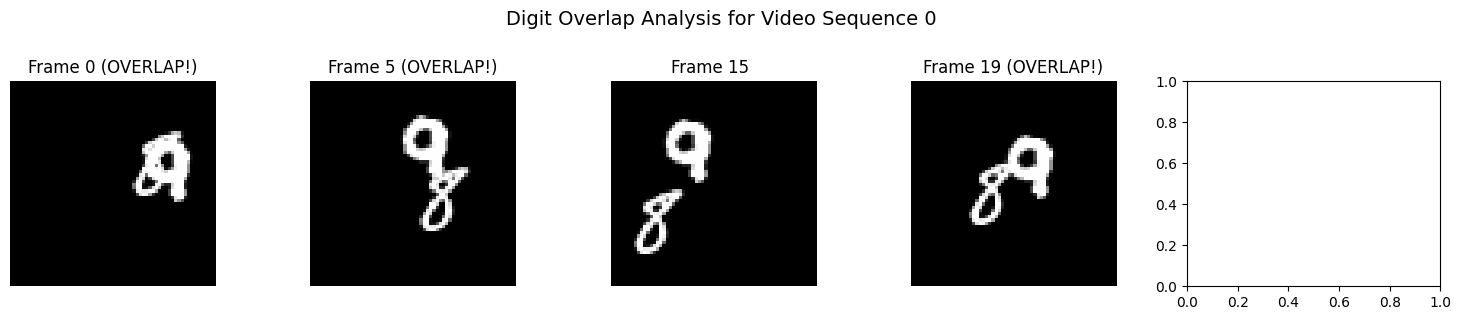

In [ ]:
# Let's visualize one sequence with its overlapping frames
if len(overlap_results) > 0:
    vid_idx = list(overlap_results.keys())[0]
    overlap_frames = overlap_results[vid_idx]

    video_tensor = train_dataset[vid_idx]
    video_np = video_tensor.squeeze().cpu().numpy()

    # Select a few frames to show: some normal ones and the overlapping ones
    fig, axes = plt.subplots(1, 5, figsize=(15, 3))
    # We'll plot frames 0, 5, 10, 15, and the first detected overlapping frame
    frames_to_show = [0, 5, overlap_frames[0], 15, 19]
    # Ensure unique and sorted indices
    frames_to_show = sorted(list(set(frames_to_show)))

    for ax, f_idx in zip(axes, frames_to_show):
        ax.imshow(video_np[f_idx], cmap='gray')
        is_overlap = "(OVERLAP!)" if f_idx in overlap_frames else ""
        ax.set_title(f"Frame {f_idx} {is_overlap}")
        ax.axis('off')

    plt.suptitle(f"Digit Overlap Analysis for Video Sequence {vid_idx}", fontsize=14, y=1.05)
    plt.tight_layout()
    plt.show()

Since there are QUITE A LOT (48/50) of overlapping sequences so yes it would change our histographs in this case.

#### **Q2.2:** For each transformation, does it change the motion statistics, the digit appearance, or both? Why does this make the three of them useful as a controlled experiment?

**Answer:** For both mirroring and rotationm, the digit appearance would change as well as motion stats.For speed changes, only motion stats change, not the appearance. Since the behavior of moving digits is a bit different after these transformations, they could prove useful to test the generalizability of our model. If model fails on transformed images, we have a guide as to where the model experiences trouble.

## Baseline. finally!

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

#conv layer
class ConvLSTM(nn.Module):
    def __init__(self, in_channels, hidden=64):
        super().__init__()
        self.hidden = hidden
        # one conv makes all 4 gates (i,o,f,g) at once
        self.conv = nn.Conv2d(in_channels + hidden, 4 * hidden, 3, padding=1, bias=True, stride=1)

    def forward(self, x, h, c):
        out = self.conv(torch.cat([x, h], dim=1))
        H = self.hidden
        i = torch.sigmoid(out[:, 0*H:1*H])
        f = torch.sigmoid(out[:, 1*H:2*H])
        o = torch.sigmoid(out[:, 2*H:3*H])
        g = torch.tanh(out[:, 3*H:4*H])

        c = f * c + i * g
        h = o * torch.tanh(c)
        return h, c



In [8]:
# baseline model A
class BaselineModelA(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = ConvLSTM(16, 64)
        self.layer2 = ConvLSTM(64, 64)
        self.to_frame = nn.Conv2d(64, 16, 1)

    def step(self, frame, h1, c1, h2, c2):
        x = F.pixel_unshuffle(frame, 4)
        h1, c1 = self.layer1(x, h1, c1)
        h2, c2 = self.layer2(h1, h2, c2)
        pred = torch.sigmoid(F.pixel_shuffle(self.to_frame(h2), 4))
        return pred, h1, c1, h2, c2

    def forward(self, video): # (B, T, 1, 64,64)
        # B, T = video.shape[:2]

        zeros = lambda: torch.zeros(B, 64, 16, 16, device=video.device)
        h1, c1, h2, c2 = zeros(), zeros(), zeros(), zeros()

        preds = []
        for t in range(1, 10):
            if t<=5:
              u = video[:, t-1]
            else:
              u = pred
            pred, h1, c1, h2, c2 = self.step(u, h1, c1, h2, c2)
            preds.append(pred)

        return torch.stack(preds[4:], dim=1) # after 4th frame (5-9)

In [9]:
#checking params
a = BaselineModelA()
num_params = sum(p.numel() for p in a.parameters() if p.requires_grad)
print("params:", num_params)

params: 480784


In [ ]:
#training loop
def train_one_epoch(model, loader, opt):
    model.train()
    total, n = 0.0, 0
    for x_in, y, mask in loader:
        x_in, y, mask = x_in.to(device), y.to(device), mask.to(device)
        y_hat = model(x_in)                       # always 5 predictions
        loss = mse_loss(y_hat, y, mask)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total += loss.item() * x_in.size(0)
        n += x_in.size(0)
    return total / n


In [ ]:
#evaluation
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum, n = 0.0, 0
    se_frame = torch.zeros(5, device=device)   # for the per-frame error curve
    cnt_frame = torch.zeros(5, device=device)
    for x_in, y, mask in loader:
        x_in, y, mask = x_in.to(device), y.to(device), mask.to(device)
        y_hat = model(x_in)
        loss_sum += mse_loss(y_hat, y, mask).item() * x_in.size(0)
        n += x_in.size(0)

        se = ((y_hat - y) ** 2).mean(dim=(2, 3, 4))   # (B,5)
        se_frame += (se * mask).sum(0)
        cnt_frame += mask.sum(0)
    return loss_sum / n, se_frame / cnt_frame.clamp(min=1)